# DNN Assignment 2, Problem 2: attention and Transformers from scratch

Chosen values: model width d = 128, seeds 7, 21 and 42.

Only PyTorch is used and no pretrained weights. Attention, multi-head attention, the feed-forward layer, the encoder block and the positional encodings are written by hand in §3. No library attention or transformer layer is used. The library attention function appears in one test cell (P2.1), where it serves as the reference for checking ours.

Assumptions:
1. The seeds 7, 21 and 42 set the model initialisation, the shuffling and the HAR validation split, exactly as in Problem 1.
2. The parity check and the hand example run in float64 on CPU. All training is in float32.
3. The 3-token attention example is my own, as the instructor asked.
4. The encoder block is pre-LN: `x = x + drop(mha(ln1(x)))`, then `x = x + drop(ffn(ln2(x)))`, with d_ff = 4d = 512 and dropout 0.1.
5. Task A uses patches of 8 time steps plus a CLS token, 2 blocks and 4 heads. Splits, normalisation and budget (Adam 1e-3, batch 64, 30 epochs) are the same as in the Problem 1 HAR runs.
6. Task B uses AdamW (lr 1e-3, weight decay 0.01) with a 200-step warm-up and then cosine decay to 0.1 times the lr, 5,000 steps, batch 64, context 128 and clipping at 1.0. Validation loss is measured on 50 fixed batches. Generation uses top-k 40, the prompt "ROMEO:\n" and seed 7.
7. The heads and no-mask ablations share a shorter budget of 1,500 steps, so they are only compared with each other.

## §1 Setup

In [1]:
# Imports, run settings and output folders.
import copy, csv, math, os, pickle, random, re, textwrap, time, urllib.request, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.metrics import f1_score
from torch.utils.data import DataLoader, TensorDataset

SMOKE = os.environ.get("SMOKE") == "1"  # local dry run only (1 seed, tiny budgets); never set on Colab
ALL_SEEDS = [7, 21, 42]
SEEDS = ALL_SEEDS[:1] if SMOKE else ALL_SEEDS
EPOCHS = 1 if SMOKE else 30  # HAR epochs (same as Problem 1)
LM_STEPS = 20 if SMOKE else 5000  # P2.4 and bonus
SHORT_STEPS = 10 if SMOKE else 1500  # P2.5b/c ablations
D = 128  # chosen model width

if Path.cwd().name != "problem2":  # Colab starts in /content: step into the uploaded folder
    _c = [p for p in [Path("problem2"), *Path.cwd().glob("*/problem2")] if p.is_dir()]
    assert _c, f"problem2/ folder not found under {Path.cwd()}; upload the project tree"
    os.chdir(_c[0])
DATA_DIR, FIG_DIR, CACHE_DIR, CSV_PATH = Path("./data"), Path("./figures"), Path("./cache"), Path("../results.csv")
for d in (DATA_DIR, FIG_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("torch", torch.__version__, "| device:", DEVICE, "| epochs:", EPOCHS, "| LM steps:", LM_STEPS, "| seeds:", SEEDS)


# Wait for queued GPU work to finish so wall-clock timings are real.
def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elif DEVICE.type == "mps":
        torch.mps.synchronize()


# Seed every random generator we use (Python, NumPy, torch CPU and CUDA).
def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

torch 2.14.1+cu130 | device: cuda | epochs: 30 | LM steps: 5000 | seeds: [7, 21, 42]


### results.csv logger and run cache
Every finished run adds one row to `../results.csv` (an older row for the same run is replaced) and is pickled to `./cache`. If Colab disconnects, running the notebook again loads the finished runs from the cache. A fresh session has no cache, so everything is trained.

In [2]:
# results.csv logger, same as in Problem 1.
COLUMNS = ["problem", "model", "seed", "seq_len", "test_acc", "macro_f1", "test_mse", "params",
           "sec_per_epoch", "val_loss_nats", "bits_per_char", "notes"]
KEY = ("problem", "model", "seed", "seq_len", "notes")


# Add one row to results.csv, or replace the old row for the same run. Writes a temp file first.
def upsert_row(row):
    assert set(row) <= set(COLUMNS), set(row) - set(COLUMNS)
    row = {c: "" if row.get(c) is None else row[c] for c in COLUMNS}
    rows = list(csv.DictReader(open(CSV_PATH, newline=""))) if CSV_PATH.exists() else []
    k = tuple(str(row[c]) for c in KEY)
    rows = [r for r in rows if tuple(r[c] for c in KEY) != k] + [row]
    tmp = CSV_PATH.with_suffix(".tmp")
    with open(tmp, "w", newline="") as f:
        w = csv.DictWriter(f, COLUMNS)
        w.writeheader()
        w.writerows(rows)
    tmp.replace(CSV_PATH)


# Train once and pickle the result; after a disconnect the pickle is loaded instead.
def run_cached(problem, model, seed, seq_len, notes, fn):
    p = CACHE_DIR / (re.sub(r"[^A-Za-z0-9=.-]+", "_", f"{problem}_{model}_s{seed}_L{seq_len}_{notes}") + ".pkl")
    if p.exists():
        out = pickle.load(open(p, "rb"))
    else:
        out = fn()
        out["row"].update(problem=problem, model=model, seed=seed, seq_len=seq_len, notes=notes)
        pickle.dump(out, open(p, "wb"))
    upsert_row(out["row"])
    return out

### Plot style and helpers

In [3]:
# Plot style, same as Problem 1.
COLORS = {"LSTM": "#2E86AB", "Transformer": "#7B2CBF", "ref": "#888888"}
plt.rcParams.update({
    "axes.grid": True, "axes.grid.axis": "y", "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 12, "axes.titlesize": 13, "axes.titleweight": "bold",
    "savefig.dpi": 200, "savefig.bbox": "tight",
})


# Format a list of seed results as 'mean ± std' (sample std, ddof=1).
def mean_std(xs, fmt="{:.4f}"):
    xs = np.asarray(xs, float)
    if len(xs) < 2:
        return fmt.format(xs.mean())
    return f"{fmt.format(xs.mean())} ± {fmt.format(xs.std(ddof=1))}"  # sample std


# Write each line's label at its right end, spaced out so labels don't collide.
def end_labels(ax, ends, gap=0.07):
    lo, hi = ax.get_ylim()
    ends = sorted(ends, key=lambda e: e[1])
    ys = [e[1] for e in ends]
    for i in range(1, len(ys)):
        ys[i] = max(ys[i], ys[i - 1] + gap * (hi - lo))
    for (x, y, lab, c), ty in zip(ends, ys):
        ax.annotate(lab, xy=(x, y), xytext=(1.02, ty), textcoords=("axes fraction", "data"), color=c, va="center",
                    fontsize=11, annotation_clip=False, arrowprops=dict(arrowstyle="-", color=c, lw=0.8, alpha=0.7))


# Grey dashed reference line with a small text label.
def ref_line(ax, y, text):
    ax.axhline(y, color=COLORS["ref"], ls="--", lw=1)
    ax.annotate(text, (1, y), xycoords=("axes fraction", "data"), xytext=(-4, 3), textcoords="offset points",
                ha="right", color=COLORS["ref"], fontsize=9)


# Save a figure to ./figures as PNG.
def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    print("saved", FIG_DIR / f"{name}.png")

## §2 Data
### HAR (Task A)
Same files, same split per seed and same normalisation (train-part statistics only) as in Problem 1, so P2.3 can be compared directly with P1.3.

In [4]:
# HAR loading copied from Problem 1, so splits and normalisation are identical.
CHANNELS = ["body_acc_x", "body_acc_y", "body_acc_z", "body_gyro_x", "body_gyro_y", "body_gyro_z",
            "total_acc_x", "total_acc_y", "total_acc_z"]
HAR_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"


# Download and unzip UCI HAR the first time; afterwards just return the folder.
def download_har(root=DATA_DIR):
    target = root / "UCI HAR Dataset"
    if not (target / "train" / "Inertial Signals").exists():
        urllib.request.urlretrieve(HAR_URL, root / "har.zip")
        zipfile.ZipFile(root / "har.zip").extractall(root)
        if (root / "UCI HAR Dataset.zip").exists():
            zipfile.ZipFile(root / "UCI HAR Dataset.zip").extractall(root)
    assert (target / "train" / "Inertial Signals").exists(), "HAR extraction failed"
    return target


# Read the 9 inertial channels, labels and subject IDs for the train and test files.
def load_har(root):
    def split(name):
        d = root / name
        X = np.stack([np.loadtxt(d / "Inertial Signals" / f"{c}_{name}.txt", dtype=np.float32) for c in CHANNELS], -1)
        y = np.loadtxt(d / f"y_{name}.txt", dtype=np.int64) - 1  # labels 1..6 -> 0..5
        s = np.loadtxt(d / f"subject_{name}.txt", dtype=np.int64)
        return X, y, s  # X:(N,128,9)

    return (*split("train"), *split("test"))


# Validation = 4 of the 21 training subjects, chosen by the seed.
def make_split(subj_train, seed):
    """Returns (train-part indices, val indices, val subjects)."""
    val_subj = np.random.default_rng(seed).choice(np.unique(subj_train), 4, replace=False)
    is_val = np.isin(subj_train, val_subj)
    return np.where(~is_val)[0], np.where(is_val)[0], np.sort(val_subj)


# Per-channel mean and std from the train part only.
def fit_norm(X):
    """Mean and std over windows and time for each channel -> two (9,) arrays."""
    return X.mean(axis=(0, 1)), X.std(axis=(0, 1))


# Standardise with the train-part statistics.
def apply_norm(X, mu, sd):
    return ((X - mu) / sd).astype(np.float32)


# Load, check, and print the validation subjects (they must match Problem 1).
X_tr, y_tr, s_tr, X_te, y_te, s_te = load_har(download_har())
assert X_tr.shape == (7352, 128, 9) and X_te.shape == (2947, 128, 9)
assert len(np.unique(s_tr)) == 21 and len(np.unique(s_te)) == 9 and not set(s_tr) & set(s_te)
for seed in ALL_SEEDS:
    tri, vai, vs = make_split(s_tr, seed)
    assert not set(s_tr[tri]) & set(s_tr[vai]) and len(tri) + len(vai) == len(s_tr)
    print(f"seed {seed}: val subjects {vs.tolist()} (same as Problem 1)")


# Loaders for one seed: split by subject, normalise, batch.
def har_loaders(seed, bs=64):
    tri, vai, _ = make_split(s_tr, seed)
    mu, sg = fit_norm(X_tr[tri])
    if SMOKE:
        tri = tri[:512]
    mk = lambda X, y: TensorDataset(torch.from_numpy(apply_norm(X, mu, sg)), torch.from_numpy(y))
    g = torch.Generator().manual_seed(seed)
    return (DataLoader(mk(X_tr[tri], y_tr[tri]), bs, shuffle=True, generator=g),
            DataLoader(mk(X_tr[vai], y_tr[vai]), 256), DataLoader(mk(X_te, y_te), 256))

seed 7: val subjects [19, 22, 27, 28] (same as Problem 1)
seed 21: val subjects [8, 14, 21, 23] (same as Problem 1)
seed 42: val subjects [3, 16, 22, 23] (same as Problem 1)


### Tiny Shakespeare (Task B)
The vocabulary comes from the whole text (65 characters). The split is by position: the first 90% is training data and the last 10% validation, without shuffling.

In [5]:
# Tiny Shakespeare: download once, build the character vocabulary, split 90/10 by position.
SHAKES_URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
SHAKES_PATH = DATA_DIR / "shakespeare.txt"
if not SHAKES_PATH.exists():
    urllib.request.urlretrieve(SHAKES_URL, SHAKES_PATH)
TEXT = SHAKES_PATH.read_text(encoding="utf-8")
VOCAB = sorted(set(TEXT))
stoi = {c: i for i, c in enumerate(VOCAB)}
V = len(VOCAB)


# Text to a tensor of character ids.
def encode(s):
    return torch.tensor([stoi[c] for c in s], dtype=torch.long)  # (len(s),)


# Character ids back to text.
def decode(ids):
    return "".join(VOCAB[int(i)] for i in ids)


DATA_ALL = encode(TEXT)  # (N,)
N_TR = int(0.9 * len(DATA_ALL))
TRAIN_IDS, VAL_IDS = DATA_ALL[:N_TR], DATA_ALL[N_TR:]  # contiguous, no shuffle
assert V == 65 and len(TRAIN_IDS) + len(VAL_IDS) == len(TEXT) and decode(encode(TEXT[:200])) == TEXT[:200]
print(f"Shakespeare: {len(TEXT):,} chars | vocab {V} | train {len(TRAIN_IDS):,} | val {len(VAL_IDS):,}")

Shakespeare: 1,115,394 chars | vocab 65 | train 1,003,854 | val 111,540


## §3 Attention and encoder block from scratch
### Scaled dot-product attention (P2.1)
`attention(Q, K, V, mask)` computes `softmax(Q K^T / sqrt(d_k)) V`. The mask is boolean, and True means the query may attend to that key. Masked scores are set to `-inf` before the softmax, so their weights come out as exactly 0.

In [6]:
# Lower-triangular boolean mask: position i may look at positions 0..i.
def causal_mask(L, device=None):
    """(L,L) bool, True where query i may attend to key j (j <= i)."""
    return torch.tril(torch.ones(L, L, dtype=torch.bool, device=device))


# Scaled dot-product attention. Returns the output and the attention weights.
def attention(Q, K, V, mask=None):
    """Q:(B,H,Lq,dk) K:(B,H,Lk,dk) V:(B,H,Lk,dv); mask broadcastable to (B,H,Lq,Lk), True = keep."""
    scores = Q @ K.transpose(-2, -1) / math.sqrt(Q.shape[-1])  # (B,H,Lq,dk) @ (B,H,dk,Lk) -> (B,H,Lq,Lk)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))  # (B,H,Lq,Lk)
    weights = torch.softmax(scores, dim=-1)  # (B,H,Lq,Lk), each row sums to 1
    return weights @ V, weights  # out (B,H,Lq,dv), weights (B,H,Lq,Lk)

#### P2.1 checks (float64, CPU)
The library attention function is used only here, as a reference.

In [7]:
# P2.1 checks on random inputs: rows sum to 1, match the library reference, zeros above the diagonal.
g = torch.Generator().manual_seed(0)
Q, K, Vv = (torch.randn(2, 3, 7, 16, dtype=torch.float64, generator=g) for _ in range(3))  # (B,H,L,dk)
o_nm, w_nm = attention(Q, K, Vv)
o_cm, w_cm = attention(Q, K, Vv, causal_mask(7))
assert torch.allclose(w_nm.sum(-1), torch.ones(2, 3, 7, dtype=torch.float64), atol=1e-6)  # (1) rows sum to 1
assert torch.allclose(w_cm.sum(-1), torch.ones(2, 3, 7, dtype=torch.float64), atol=1e-6)
d_nm = (o_nm - F.scaled_dot_product_attention(Q, K, Vv)).abs().max()  # (2) matches the reference
d_cm = (o_cm - F.scaled_dot_product_attention(Q, K, Vv, is_causal=True)).abs().max()
assert d_nm < 1e-5 and d_cm < 1e-5
upper = torch.triu(torch.ones(7, 7, dtype=torch.bool), 1)
assert (w_cm[..., upper] == 0).all() and (w_nm[..., upper] > 0).all()  # (3) causal: exactly 0 above the diagonal
print(f"P2.1 ok | max|Δ| vs reference: no mask {d_nm:.1e}, causal {d_cm:.1e}")

P2.1 ok | max|Δ| vs reference: no mask 4.4e-16, causal 2.2e-16


#### Hand example (3 tokens, d_k = 2)
Q = K = [[1,0],[0,1],[1,1]], V = [[1,2],[3,4],[5,6]].

Scores = Q K^T / sqrt(2) = [[0.7071, 0, 0.7071], [0, 0.7071, 0.7071], [0.7071, 0.7071, 1.4142]].

Row 1 worked out in full: exp(0.7071) = 2.0281, exp(0) = 1, so the sum is 2.0281 + 1 + 2.0281 = 5.0562 and the weights are 2.0281/5.0562 = 0.4011, 1/5.0562 = 0.1978, 0.4011. Output row 1 = 0.4011·[1,2] + 0.1978·[3,4] + 0.4011·[5,6] = [0.4011+0.5934+2.0055, 0.8022+0.7912+2.4066] = [3, 4].

Row 2: scores [0, 0.7071, 0.7071] → exp = [1, 2.0281, 2.0281], sum 5.0562 → [0.1978, 0.4011, 0.4011]; output = 0.1978·[1,2] + 0.4011·[3,4] + 0.4011·[5,6] = [3.4067, 4.4067].

Row 3: scores [0.7071, 0.7071, 1.4142] → exp = [2.0281, 2.0281, 4.1133], sum 8.1695 → [0.2483, 0.2483, 0.5035]; output = 0.2483·[1,2] + 0.2483·[3,4] + 0.5035·[5,6] = [3.5105, 4.5105].

Causal mask (token i sees tokens ≤ i): row 1 = [1, 0, 0]; row 2 scores [0, 0.7071] give [1, 2.0281]/3.0281 = [0.3302, 0.6698, 0]; row 3 is unchanged. Causal output = [[1, 2], [2.3395, 3.3395], [3.5105, 4.5105]].

In [8]:
# Hand example: the code must reproduce the numbers worked out above.
f64 = lambda a: torch.tensor(a, dtype=torch.float64)
Qt, Vt = f64([[1, 0], [0, 1], [1, 1]]), f64([[1, 2], [3, 4], [5, 6]])
TOY_O, TOY_W = attention(Qt, Qt, Vt)  # 2-D (L,dk) inputs go through the same matmuls
TOY_OC, TOY_WC = attention(Qt, Qt, Vt, causal_mask(3))
assert torch.allclose(
    TOY_W, f64([[0.4011, 0.1978, 0.4011], [0.1978, 0.4011, 0.4011], [0.2483, 0.2483, 0.5035]]), atol=1e-4
)
assert torch.allclose(TOY_O, f64([[3, 4], [3.4067, 4.4067], [3.5105, 4.5105]]), atol=1e-4)
assert torch.allclose(TOY_WC, f64([[1, 0, 0], [0.3302, 0.6698, 0], [0.2483, 0.2483, 0.5035]]), atol=1e-4)
assert torch.allclose(TOY_OC, f64([[1, 2], [2.3395, 3.3395], [3.5105, 4.5105]]), atol=1e-4)
print("hand example matches code (atol 1e-4)")
print("unmasked weights\n", TOY_W.numpy().round(4), "\noutput\n", TOY_O.numpy().round(4))
print("causal weights\n", TOY_WC.numpy().round(4), "\noutput\n", TOY_OC.numpy().round(4))

hand example matches code (atol 1e-4)
unmasked weights
 [[0.4011 0.1978 0.4011]
 [0.1978 0.4011 0.4011]
 [0.2483 0.2483 0.5035]] 
output
 [[3.     4.    ]
 [3.4067 4.4067]
 [3.5105 4.5105]]
causal weights
 [[1.     0.     0.    ]
 [0.3302 0.6698 0.    ]
 [0.2483 0.2483 0.5035]] 
output
 [[1.     2.    ]
 [2.3395 3.3395]
 [3.5105 4.5105]]


#### P2-F1 Toy attention heatmaps

saved figures/p2_fig01_toy_attention.png


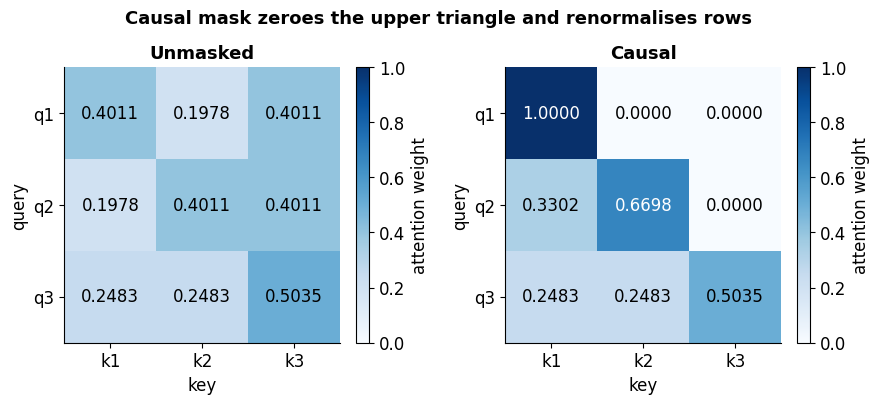

In [9]:
# P2-F1: the unmasked and causal weight matrices.
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, W, ttl in zip(axes, (TOY_W, TOY_WC), ("Unmasked", "Causal")):
    im = ax.imshow(W.numpy(), cmap="Blues", vmin=0, vmax=1)
    ax.grid(False)
    ax.set_xticks(range(3), ["k1", "k2", "k3"])
    ax.set_yticks(range(3), ["q1", "q2", "q3"])
    ax.set_xlabel("key")
    ax.set_ylabel("query")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{W[i, j]:.4f}", ha="center", va="center", color="white" if W[i, j] > 0.6 else "black")
    ax.set_title(ttl)
    fig.colorbar(im, ax=ax, fraction=0.046, label="attention weight")
fig.suptitle("Causal mask zeroes the upper triangle and renormalises rows", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "p2_fig01_toy_attention")
plt.show()

### Multi-head attention, feed-forward, encoder block, positional encodings (P2.2)
`MultiHeadAttention` has four `nn.Linear(d, d)` layers with bias (`W_q`, `W_k`, `W_v`, `W_o`) and calls our `attention`. The block is pre-LN: LayerNorm is applied before each sub-layer, and the residual path has no normalisation on it.

In [10]:
# Multi-head attention built on our attention(): project, split into heads, attend, merge, project.
class MultiHeadAttention(nn.Module):
    def __init__(self, d, n_heads):
        super().__init__()
        assert d % n_heads == 0, f"d={d} must be divisible by n_heads={n_heads}"
        self.d, self.h, self.dk = d, n_heads, d // n_heads
        self.W_q, self.W_k, self.W_v, self.W_o = (nn.Linear(d, d) for _ in range(4))  # each (d -> d), with bias

    # Reshape (B, L, d) into H heads of size d/H.
    def split(self, t):
        B, L, _ = t.shape
        return t.view(B, L, self.h, self.dk).transpose(1, 2)  # (B,L,d) -> (B,L,H,dk) -> (B,H,L,dk)

    def forward(self, x, mask=None):  # x:(B,L,d)
        B, L, _ = x.shape
        Q, K, V = self.split(self.W_q(x)), self.split(self.W_k(x)), self.split(self.W_v(x))  # each (B,H,L,dk)
        out, w = attention(Q, K, V, mask)  # out (B,H,L,dk), w (B,H,L,L)
        out = out.transpose(1, 2).contiguous().view(B, L, self.d)  # (B,H,L,dk) -> (B,L,H,dk) -> (B,L,d)
        return self.W_o(out), w  # (B,L,d), (B,H,L,L)


# Position-wise feed-forward: Linear, GELU, Dropout, Linear.
class FeedForward(nn.Module):
    def __init__(self, d, d_ff, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, d_ff), nn.GELU(), nn.Dropout(dropout), nn.Linear(d_ff, d))

    def forward(self, x):  # (B,L,d) -> (B,L,d_ff) -> (B,L,d)
        return self.net(x)


# Pre-LN encoder block. Also returns the attention weights for the heatmaps.
class EncoderBlock(nn.Module):
    """Pre-LN: x = x + drop(mha(ln1(x), mask)); x = x + drop(ffn(ln2(x)))."""

    def __init__(self, d, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.mha = MultiHeadAttention(d, n_heads)
        self.ffn = FeedForward(d, d_ff, dropout)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask=None):  # x:(B,L,d) -> (B,L,d), weights (B,H,L,L)
        a, w = self.mha(self.ln1(x), mask)
        x = x + self.drop(a)
        x = x + self.drop(self.ffn(self.ln2(x)))
        return x, w


# Fixed sin/cos positional encoding, added to the input.
class SinusoidalPE(nn.Module):
    def __init__(self, d, max_len=1024):  # max_len covers context 512 in P2.5d
        super().__init__()
        pos = torch.arange(max_len, dtype=torch.float32)[:, None]  # (max_len,1)
        freq = torch.exp(-math.log(10000.0) * torch.arange(0, d, 2, dtype=torch.float32) / d)  # (d/2,)
        pe = torch.zeros(max_len, d)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * freq), torch.cos(pos * freq)  # even = sin, odd = cos
        self.register_buffer("pe", pe[None])  # (1,max_len,d)

    def forward(self, x):  # (B,L,d) -> (B,L,d)
        return x + self.pe[:, : x.shape[1]]


# Learned positional encoding (one embedding vector per position), used in the P2.3 ablation.
class LearnedPE(nn.Module):
    def __init__(self, max_len, d):
        super().__init__()
        self.emb = nn.Embedding(max_len, d)

    def forward(self, x):  # (B,L,d) -> (B,L,d)
        return x + self.emb(torch.arange(x.shape[1], device=x.device))[None]

#### P2-T0 Encoder parameter count
One block with width d and feed-forward width d_ff (biases included):

- MHA: four d×d projections give 4d² weights and 4d biases.
- FFN: Linear(d, d_ff) and Linear(d_ff, d) give 2·d·d_ff weights and d_ff + d biases.
- Two LayerNorms: d scale and d shift each, 4d in total.

Total = 4d² + 2·d·d_ff + 9d + d_ff.

| Component | Formula | d=128, d_ff=512 |
|---|---|---|
| Weight matrices | 4d² + 2·d·d_ff | 196,608 |
| MHA biases | 4d | 512 |
| FFN biases | d_ff + d | 640 |
| 2× LayerNorm | 4d | 512 |
| Total | 4d² + 2·d·d_ff + 9d + d_ff | 198,272 |

In [11]:
# P2-T0: parameter count of one block, weights only and in total.
block_params = lambda d, d_ff: 4 * d * d + 2 * d * d_ff + 9 * d + d_ff
blk = EncoderBlock(D, 4, 512)
assert sum(p.numel() for p in blk.parameters() if p.dim() >= 2) == 196_608  # weight matrices only
assert sum(p.numel() for p in blk.parameters()) == block_params(D, 512) == 198_272
print("P2-T0 ok | weights 196,608 + biases/LayerNorm 1,664 = 198,272 per block")

# Output shapes of MHA and the block.
x = torch.randn(2, 16, D)
o, w = MultiHeadAttention(D, 4)(x)
assert o.shape == (2, 16, D) and w.shape == (2, 4, 16, 16) and blk(x)[0].shape == (2, 16, D)

# causal leak test: perturb tokens after t; with the mask, outputs at positions <= t must not change
blk.eval()
cm = causal_mask(16)
with torch.no_grad():
    for t in (3, 8):
        xp = x.clone()
        xp[:, t + 1 :] += 100 * torch.randn_like(xp[:, t + 1 :])
        dc = (blk(xp, cm)[0][:, : t + 1] - blk(x, cm)[0][:, : t + 1]).abs().max().item()
        dn = (blk(xp)[0][:, : t + 1] - blk(x)[0][:, : t + 1]).abs().max().item()
        assert dc < 1e-6 and dn > 1e-3, (t, dc, dn)
        print(f"leak test t={t}: causal max|Δ| = {dc:.1e} | without mask {dn:.2f} (changes, so the test can fail)")
assert SinusoidalPE(D)(torch.zeros(1, 512, D)).shape == (1, 512, D)
assert LearnedPE(17, D)(torch.zeros(2, 17, D)).shape == (2, 17, D)

P2-T0 ok | weights 196,608 + biases/LayerNorm 1,664 = 198,272 per block
leak test t=3: causal max|Δ| = 0.0e+00 | without mask 0.38 (changes, so the test can fail)
leak test t=8: causal max|Δ| = 0.0e+00 | without mask 0.28 (changes, so the test can fail)


## §4 Experiments
### P2.3 Task A: HAR classification with our Transformer
`HARTransformer` cuts the 128-step window `(B,128,9)` into 16 patches of 8 steps `(B,16,72)` and embeds each patch to d = 128. A learnable CLS token goes in front (17 tokens), and a positional encoding is added (`none`, `sinusoidal` or `learned`). Then come 2 pre-LN encoder blocks (4 heads, dropout 0.1, no mask), a final LayerNorm and a linear head on the CLS token. The budget is the same for the three modes and for P1.3: Adam lr 1e-3, batch 64, 30 epochs, no clipping. The best epoch is picked on validation and the test set is evaluated once with those weights.

In [12]:
# Task A model: patch embedding, CLS token, positional encoding, 2 encoder blocks, linear head on CLS.
class HARTransformer(nn.Module):
    def __init__(self, pos="sinusoidal", d=D, n_heads=4, n_layers=2, dropout=0.1):
        super().__init__()
        self.embed = nn.Linear(72, d)  # (B,16,72) -> (B,16,d)
        self.cls = nn.Parameter(torch.randn(1, 1, d) * 0.02)  # learnable CLS token
        self.pe = {"none": nn.Identity, "sinusoidal": lambda: SinusoidalPE(d), "learned": lambda: LearnedPE(17, d)}[
            pos
        ]()
        self.blocks = nn.ModuleList([EncoderBlock(d, n_heads, 4 * d, dropout) for _ in range(n_layers)])
        self.ln = nn.LayerNorm(d)
        self.head = nn.Linear(d, 6)

    def forward(self, x):  # x:(B,128,9)
        B = x.shape[0]
        x = self.embed(x.reshape(B, 16, 72))  # 8 consecutive steps per patch -> (B,16,d)
        x = self.pe(torch.cat([self.cls.expand(B, -1, -1), x], 1))  # (B,17,d)
        for blk in self.blocks:
            x = blk(x)[0]  # (B,17,d), no mask
        return self.head(self.ln(x)[:, 0])  # CLS -> logits (B,6)


# Total number of parameters.
def n_params(m):
    return sum(p.numel() for p in m.parameters())


# Mean cross-entropy, accuracy and macro-F1 on a loader.
@torch.no_grad()
def evaluate(model, dl):
    model.eval()
    tot, preds, ys = 0.0, [], []
    for x, y in dl:
        out = model(x.to(DEVICE))
        tot += float(F.cross_entropy(out, y.to(DEVICE), reduction="sum"))
        preds.append(out.argmax(1).cpu())
        ys.append(y)
    p, t = torch.cat(preds).numpy(), torch.cat(ys).numpy()
    return dict(loss=tot / len(t), acc=float((p == t).mean()), f1=float(f1_score(t, p, average="macro")))


# Training loop for the HAR Transformer, same protocol as Problem 1.
def fit(model, train_dl, val_dl, epochs):
    """Adam lr 1e-3, no clipping (as in P1.3). Keeps the epoch with the best validation accuracy; returns (history, s/epoch)."""
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    hist = dict(train_loss=[], val_loss=[])
    best, best_state, times = -1.0, None, []
    for ep in range(epochs):
        model.train()
        sync()
        t0 = time.time()
        tot, n = 0.0, 0
        for x, y in train_dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(x), y)
            loss.backward()
            opt.step()
            tot, n = tot + loss.item() * len(y), n + len(y)
        sync()
        times.append(time.time() - t0)
        assert math.isfinite(tot), f"non-finite training loss at epoch {ep}"
        ev = evaluate(model, val_dl)
        hist["train_loss"].append(tot / n)
        hist["val_loss"].append(ev["loss"])
        if ev["acc"] > best:
            best, best_state = ev["acc"], {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return hist, float(np.mean(times))


# Check output shape and model size for each positional mode (learned PE adds 17 x d).
PE_MODES = ["none", "sinusoidal", "learned"]
p0 = n_params(HARTransformer("none"))
for mode in PE_MODES:
    m = HARTransformer(mode)
    assert m(torch.randn(3, 128, 9)).shape == (3, 6) and n_params(m) == p0 + (17 * D if mode == "learned" else 0)
print(f"HARTransformer params: {p0:,} (none, sinusoidal) | {p0 + 17 * D:,} (learned)")

HARTransformer params: 407,046 (none, sinusoidal) | 409,222 (learned)


In [13]:
# One HAR run: train, then evaluate the test set once at the best validation epoch.
def run_har_tf(mode, seed):
    seed_all(seed)
    model = HARTransformer(mode).to(DEVICE)
    train_dl, val_dl, test_dl = har_loaders(seed, bs=64)
    hist, spe = fit(model, train_dl, val_dl, EPOCHS)
    te = evaluate(model, test_dl)  # test set used once, with the best-val weights
    row = dict(test_acc=te["acc"], macro_f1=te["f1"], params=n_params(model), sec_per_epoch=spe)
    return dict(row=row, history=hist, artifacts={})


t0 = time.time()
# 3 positional modes x 3 seeds.
TF = {m: [run_cached("P2.3", "Transformer", s, 128, f"d={D},pos={m}", lambda m=m, s=s: run_har_tf(m, s)) for s in SEEDS]
      for m in PE_MODES}
for m in PE_MODES:
    print(f"P2.3 pos={m:10s}: acc " + ", ".join(f"{o['row']['test_acc']:.4f}" for o in TF[m]))
print(f"P2.3 done in {time.time() - t0:.0f}s")

P2.3 pos=none      : acc 0.9294, 0.9155, 0.9264
P2.3 pos=sinusoidal: acc 0.9186, 0.8968, 0.9026
P2.3 pos=learned   : acc 0.9233, 0.9118, 0.8982
P2.3 done in 250s


#### P2-T1 Best Problem 1 model vs Transformer, P2-T2 positional-encoding ablation
The Problem 1 rows are read from `../results.csv` (`problem == P1.3`), so Problem 1 has to be run first. The table shows the Problem 1 model with the highest mean test accuracy.

In [14]:
# P2-T1 (best P1.3 model vs Transformer) and P2-T2 (positional ablation).
stats = lambda acc, f1, params, spe: (mean_std(acc), mean_std(f1), f"{int(params):,}", f"{np.mean(spe):.2f}")
tf_stats = lambda runs: stats([o["row"]["test_acc"] for o in runs], [o["row"]["macro_f1"] for o in runs],
                               runs[0]["row"]["params"], [o["row"]["sec_per_epoch"] for o in runs])
p1 = pd.read_csv(CSV_PATH, keep_default_na=False)
p1 = p1[p1.problem == "P1.3"]
cols = ["test acc (mean ± std)", "macro-F1 (mean ± std)", "params", "s/epoch"]
rows = []
if len(p1) or not SMOKE:
    assert len(p1), "run problem1 first: no P1.3 rows in ../results.csv"
    best = p1.assign(test_acc=p1.test_acc.astype(float)).groupby("model").test_acc.mean().idxmax()
    r = p1[p1.model == best]
    rows.append((f"{best} (best of P1.3)", *stats(r.test_acc.astype(float), r.macro_f1.astype(float),
                                                  r.params.iloc[0], r.sec_per_epoch.astype(float))))
rows.append(("Transformer (sinusoidal)", *tf_stats(TF["sinusoidal"])))
display(Markdown(f"**P2-T1** best Problem 1 model vs Transformer, {len(SEEDS)} seeds, {EPOCHS} epochs, device {DEVICE.type}"),
        pd.DataFrame(rows, columns=["model", *cols]))
display(Markdown("**P2-T2** positional-encoding ablation"),
        pd.DataFrame([(m, *tf_stats(TF[m])) for m in PE_MODES], columns=["positional encoding", *cols]))

**P2-T1** best Problem 1 model vs Transformer, 3 seeds, 30 epochs, device cuda

,model,test acc (mean ± std),macro-F1 (mean ± std),params,s/epoch
0,GRU (best of P1.3),0.9115 ± 0.0061,0.9123 ± 0.0069,"54,150",0.30
1,Transformer (sinusoidal),0.9060 ± 0.0112,0.9069 ± 0.0114,"407,046",0.84


**P2-T2** positional-encoding ablation

,positional encoding,test acc (mean ± std),macro-F1 (mean ± std),params,s/epoch
0,none,0.9238 ± 0.0073,0.9233 ± 0.0073,"407,046",0.84
1,sinusoidal,0.9060 ± 0.0112,0.9069 ± 0.0114,"407,046",0.84
2,learned,0.9111 ± 0.0126,0.9112 ± 0.0134,"409,222",0.88


saved figures/p2_fig02_pos_ablation.png


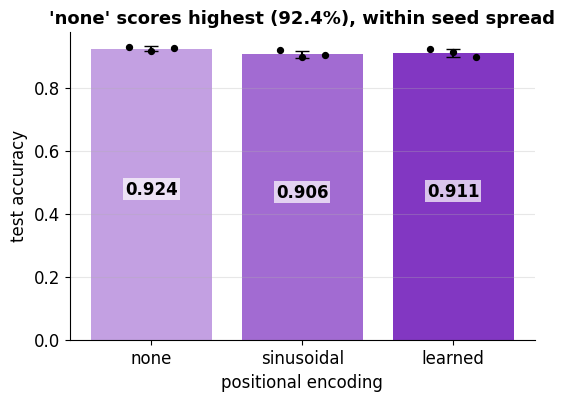

In [15]:
# P2-F2: accuracy per positional mode, with one dot per seed.
accs = {m: np.array([o["row"]["test_acc"] for o in TF[m]]) for m in PE_MODES}
top = max(PE_MODES, key=lambda m: accs[m].mean())
fig, ax = plt.subplots(figsize=(6, 4))
for i, (m, al) in enumerate(zip(PE_MODES, (0.45, 0.7, 0.95))):
    a = accs[m]
    ax.bar(i, a.mean(), yerr=a.std(ddof=1) if len(a) > 1 else 0, color=COLORS["Transformer"], alpha=al, capsize=5)
    ax.scatter(i + np.linspace(-0.15, 0.15, len(a)), a, color="black", s=18, zorder=3)
    ax.text(i, a.mean() / 2, f"{a.mean():.3f}", ha="center", fontweight="bold",
            bbox=dict(fc="white", ec="none", alpha=0.7, pad=1.5))
ax.set_xticks(range(3), PE_MODES)
ax.set_xlabel("positional encoding")
ax.set_ylabel("test accuracy")
ax.set_title(f"'{top}' scores highest ({accs[top].mean():.1%}), within seed spread")
save(fig, "p2_fig02_pos_ablation")
plt.show()

Reading P2-T1 and P2-F2. The Transformer with sinusoidal PE (407,046 parameters) reaches 0.9060 ± 0.0112, against 0.9115 ± 0.0061 for the best Problem 1 model, the GRU (54,150 parameters). The difference is within one standard deviation, but the Transformer has 7.5 times more parameters and needs 0.84 s per epoch against 0.30 s. In the positional ablation (P2-F2), `none` (0.9238 ± 0.0073) scores above `learned` (0.9111 ± 0.0126) and `sinusoidal` (0.9060 ± 0.0112). With 3 seeds that gap is only one to two standard deviations, so it is weak evidence. My guess, which I did not test, is that each patch already contains its 8 time steps in order, and the activity depends more on which motion patterns appear than on the order of the 16 patches.

### P2.4 Task B: character-level language model on Tiny Shakespeare
`CharTransformer` is an embedding, sinusoidal PE, 4 pre-LN encoder blocks (4 heads, d_ff = 512, dropout 0.1, causal mask), a LayerNorm and a linear layer to 65 logits. With `return_attn=True` it also returns the attention weights of every layer as a list of `(B,H,L,L)` tensors. Training uses AdamW (lr 1e-3, weight decay 0.01), a linear warm-up followed by cosine decay to 0.1 times the lr, batch 64, context 128 and gradient clipping at 1.0. The validation loss is the mean over 50 fixed validation batches, drawn once with seed 0.

In [16]:
# P2.4 settings: context length and batch size.
CTX, BS_LM = 128, 64


# Task B model: character embedding, sinusoidal PE, 4 encoder blocks with a causal mask, linear head.
class CharTransformer(nn.Module):
    def __init__(self, vocab=V, d=D, n_heads=4, n_layers=4, d_ff=512, dropout=0.1, causal=True):
        super().__init__()
        self.causal = causal
        self.emb = nn.Embedding(vocab, d)
        self.pe = SinusoidalPE(d)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([EncoderBlock(d, n_heads, d_ff, dropout) for _ in range(n_layers)])
        self.ln = nn.LayerNorm(d)
        self.head = nn.Linear(d, vocab)

    def forward(self, idx, return_attn=False):  # idx:(B,L) int64
        x = self.drop(self.pe(self.emb(idx)))  # (B,L,d)
        mask = causal_mask(idx.shape[1], idx.device) if self.causal else None  # (L,L), broadcast over (B,H)
        attn = []
        for blk in self.blocks:
            x, w = blk(x, mask)  # (B,L,d), (B,H,L,L)
            attn.append(w)
        logits = self.head(self.ln(x))  # (B,L,vocab)
        return (logits, attn) if return_attn else logits


# Shape check; the causal mask must leave zeros above the diagonal.
lg, at = CharTransformer()(torch.randint(0, V, (2, 20)), return_attn=True)
assert lg.shape == (2, 20, V) and len(at) == 4 and at[-1].shape == (2, 4, 20, 20) and (at[-1].triu(1) == 0).all()
print(f"CharTransformer params: {n_params(CharTransformer()):,}")

CharTransformer params: 810,049


In [17]:
# Windows of CTX characters starting at `starts`, with targets shifted by one.
def lm_batch(data, starts):
    ix = starts[:, None] + torch.arange(CTX)[None]  # (B,CTX) positions
    return data[ix], data[ix + 1]  # inputs (B,CTX), next-char targets (B,CTX)


# Fixed validation set: 50 batches drawn once and reused by every LM run.
g = torch.Generator().manual_seed(0)  # drawn once, identical for every run
VAL_BATCHES = [[t.to(DEVICE) for t in lm_batch(VAL_IDS, torch.randint(0, len(VAL_IDS) - CTX - 1, (BS_LM,), generator=g))]
               for _ in range(50)]


# Mean validation cross-entropy over the fixed batches, in nats.
@torch.no_grad()
def lm_val_loss(model):
    model.eval()
    return float(sum(F.cross_entropy(model(x).reshape(-1, V), y.reshape(-1)) for x, y in VAL_BATCHES)) / 50  # nats


# Step-based training loop shared by every language-model run.
def train_lm(model, steps, eval_every, tag, seed=7):
    """AdamW, linear warm-up for min(200, steps/10) steps, cosine decay to 0.1*lr, clip 1.0.
    history['wall'] counts training time only (evaluation excluded)."""
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)
    warm = max(1, min(200, steps // 10))
    lam = lambda s: (
        (s + 1) / warm if s < warm else 0.1 + 0.45 * (1 + math.cos(math.pi * (s - warm) / max(1, steps - warm)))
    )
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lam)
    g = torch.Generator().manual_seed(seed)  # train windows
    hist, run, wall = dict(step=[], train_loss=[], val_loss=[], wall=[]), [], 0.0
    for step in range(1, steps + 1):
        model.train()
        x, y = (
            t.to(DEVICE) for t in lm_batch(TRAIN_IDS, torch.randint(0, len(TRAIN_IDS) - CTX - 1, (BS_LM,), generator=g))
        )
        sync()
        t0 = time.time()
        opt.zero_grad(set_to_none=True)
        loss = F.cross_entropy(model(x).reshape(-1, V), y.reshape(-1))  # (B*L,V) vs (B*L,)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        sched.step()
        sync()
        wall += time.time() - t0
        run.append(loss.item())
        assert math.isfinite(run[-1]), f"{tag}: non-finite loss at step {step}"
        if step % eval_every == 0 or step == steps:
            vl = lm_val_loss(model)
            for k, v in zip(hist, (step, np.mean(run), vl, wall)):
                hist[k].append(float(v))
            print(
                f"[{tag}] step {step:5d} train {hist['train_loss'][-1]:.4f} val {vl:.4f} ({vl / math.log(2):.3f} bpc) {wall:.0f}s"
            )
            run = []
    return hist, wall


# Train a fresh LM and package the CSV row, the history and the final weights.
def run_lm(model_fn, steps, eval_every, tag):
    seed_all(7)
    model = model_fn().to(DEVICE)
    hist, wall = train_lm(model, steps, eval_every, tag)
    vl = hist["val_loss"][-1]
    row = dict(val_loss_nats=vl, bits_per_char=vl / math.log(2), params=n_params(model))
    state = {k: v.cpu() for k, v in model.state_dict().items()}
    return dict(
        row=row, history=hist, artifacts=dict(state=state, train_sec=wall, tokens_per_s=steps * BS_LM * CTX / wall)
    )


# Rebuild a trained LM from its cached weights and check it gives the logged loss.
def load_lm(model_fn, out):
    model = model_fn().to(DEVICE)
    model.load_state_dict(out["artifacts"]["state"])
    model.eval()
    assert abs(lm_val_loss(model) - out["row"]["val_loss_nats"]) < 1e-2  # reloaded weights reproduce the logged loss
    return model


# Train the P2.4 model, or load it from the cache.
EVAL_EVERY = 10 if SMOKE else 250
LM_OUT = run_cached("P2.4", "Transformer", 7, CTX, f"d={D},heads=4,steps={LM_STEPS}",
                    lambda: run_lm(CharTransformer, LM_STEPS, EVAL_EVERY, "P2.4"))
LM, LM_HIST = load_lm(CharTransformer, LM_OUT), LM_OUT["history"]
r, a = LM_OUT["row"], LM_OUT["artifacts"]
print(f"P2.4: val {r['val_loss_nats']:.4f} nats = {r['bits_per_char']:.4f} bits/char | {a['tokens_per_s']:,.0f} tokens/s | "
      f"train {a['train_sec']:.0f}s | params {r['params']:,}")

[P2.4] step   250 train 2.7843 val 2.3142 (3.339 bpc) 8s
[P2.4] step   500 train 2.1736 val 2.0407 (2.944 bpc) 15s
[P2.4] step   750 train 1.9355 val 1.9014 (2.743 bpc) 23s
[P2.4] step  1000 train 1.7863 val 1.7961 (2.591 bpc) 31s
[P2.4] step  1250 train 1.6907 val 1.7376 (2.507 bpc) 38s
[P2.4] step  1500 train 1.6277 val 1.6939 (2.444 bpc) 46s
[P2.4] step  1750 train 1.5790 val 1.6684 (2.407 bpc) 54s
[P2.4] step  2000 train 1.5458 val 1.6455 (2.374 bpc) 62s
[P2.4] step  2250 train 1.5221 val 1.6287 (2.350 bpc) 70s
[P2.4] step  2500 train 1.4988 val 1.6137 (2.328 bpc) 78s
[P2.4] step  2750 train 1.4832 val 1.6027 (2.312 bpc) 86s
[P2.4] step  3000 train 1.4667 val 1.5918 (2.296 bpc) 94s
[P2.4] step  3250 train 1.4545 val 1.5840 (2.285 bpc) 103s
[P2.4] step  3500 train 1.4405 val 1.5795 (2.279 bpc) 114s
[P2.4] step  3750 train 1.4352 val 1.5717 (2.268 bpc) 122s
[P2.4] step  4000 train 1.4276 val 1.5679 (2.262 bpc) 131s
[P2.4] step  4250 train 1.4201 val 1.5682 (2.262 bpc) 139s
[P2.4] ste

#### P2-F3 Language-model learning curve

saved figures/p2_fig03_lm_curve.png


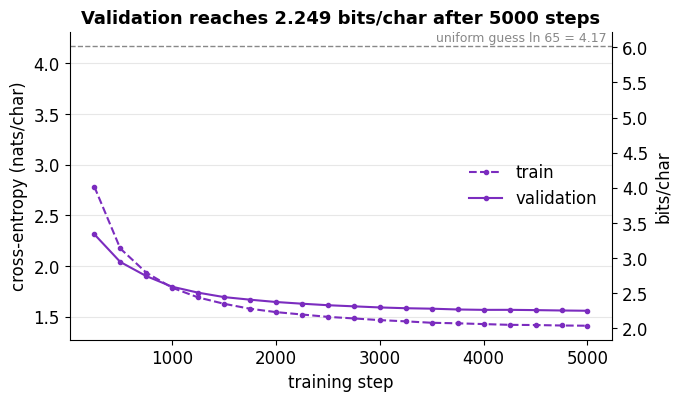

In [18]:
# P2-F3: train and validation loss, bits/char on the right axis.
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(LM_HIST["step"], LM_HIST["train_loss"], color=COLORS["Transformer"], ls="--", marker="o", ms=3, label="train")
ax.plot(LM_HIST["step"], LM_HIST["val_loss"], color=COLORS["Transformer"], marker="o", ms=3, label="validation")
ref_line(ax, math.log(65), "uniform guess ln 65 = 4.17")
ax.set_xlabel("training step")
ax.set_ylabel("cross-entropy (nats/char)")
sec = ax.secondary_yaxis("right", functions=(lambda y: y / math.log(2), lambda b: b * math.log(2)))
sec.set_ylabel("bits/char")
ax.set_title(
    f"Validation reaches {LM_HIST['val_loss'][-1] / math.log(2):.3f} bits/char after {LM_HIST['step'][-1]:.0f} steps"
)
ax.legend(frameon=False)
save(fig, "p2_fig03_lm_curve")
plt.show()

### Generation (P2.4)
Generation runs on CPU with a seeded generator. At each step the model sees the last 128 tokens, all but the top-k logits are dropped, and the next character is sampled from softmax(logits / T) with `torch.multinomial`. It returns exactly `n` new characters.

In [19]:
# Generation settings.
PROMPT, TOP_K, GEN_SEED = "ROMEO:\n", 40, 7


# Sample n characters with top-k and temperature, on CPU with a fixed seed.
@torch.no_grad()
def generate(model, n=500, temperature=0.8, prompt=PROMPT):
    m = copy.deepcopy(model).cpu().eval()
    g = torch.Generator().manual_seed(GEN_SEED)
    ids = encode(prompt).tolist()
    for _ in range(n):
        logits = m(torch.tensor(ids[-CTX:])[None])[0, -1]  # (V,) at the last position
        logits = logits.masked_fill(logits < torch.topk(logits, TOP_K).values[-1], float("-inf"))  # keep top-k
        ids.append(int(torch.multinomial(torch.softmax(logits / temperature, -1), 1, generator=g)))
    return decode(ids[len(prompt) :])  # new characters only


# The three required samples, written to generated_samples.txt.
SAMPLES = {T: generate(LM, temperature=T) for T in (0.2, 0.8, 1.5)}
assert all(len(s) == 500 for s in SAMPLES.values())
with open("generated_samples.txt", "w") as f:
    for T, s in SAMPLES.items():
        f.write(f'=== Temperature {T} (top-k={TOP_K}, seed={GEN_SEED}, prompt="ROMEO:\\n") ===\n{s}\n\n')
assert open("generated_samples.txt").read().count("=== Temperature") == 3
for T, s in SAMPLES.items():
    print(f"=== T={T} ===\n{s}\n")

=== T=0.2 ===
What shall be the sea of the senses of the state
The season of the prince of the sense of the world.

KING RICHARD III:
What is the comes of the country of the children.

KING RICHARD III:
And therefore the court of the state the country.

KING RICHARD III:
The cousin of the court of the country's death,
And let the send that hath shall be so much and so some the country.

KING RICHARD III:
What is the senators of the world of the country.

CORIOLANUS:
What we shall be the man of the constant th

=== T=0.8 ===
At 'tis encounters, I have so not streets him be now?

CLARENCE:
Romeo, sir; yet she cause the behold that we may return.

MENENIUS:
Well, now, trage own the most wester thou resk?

ESCALUS:
What they do unto the vintoney thus and shall be
And the friends with and simple are confession.
In thou dost thou wast thou shalt hath determing come
And seems to begge the successs'd moister something
Is not to be grave to his abuse of thee.

First Murderer:
I saw you will
Fro

#### Temperature discussion
The three samples in `generated_samples.txt` (top-k 40, seed 7, prompt `ROMEO:` plus a newline) come from the model that reaches 2.249 bits/char (P2-F3).
* At T = 0.2 the text is grammatical but repetitive. It keeps looping on the same phrases, for example "What is the senators of the world of the country." and "The cousin of the court of the country's death", and "of the country" comes back for several speakers.
* T = 0.8 reads most like Shakespeare. It has speaker headings (CLARENCE, MENENIUS, ESCALUS) and fairly fluent lines such as "Romeo, sir; yet she cause the behold that we may return.", though it still makes up a few words ("vintoney", "determing").
* At T = 1.5 the spelling falls apart and the lines stop making sense: "PIRDETA", "Arupce", "the Thinef", "wath warra homel".

A low temperature gives safe but repetitive text, a high one gives variety but nonsense, and 0.8 sits between the two.

### P2.5a Attention heads on a real sentence
The first validation line with 40 to 60 characters is fed to the trained P2.4 model. Two heads from the last layer are picked by a fixed rule. Head A has the highest mean weight on the previous token (the mean over t ≥ 1 of `w[t, t-1]`). Head B has the highest mean row entropy among the remaining heads. The heatmaps show only the last 24 characters so the axis labels stay readable.

line (48 chars): 'And you, good sir! Pray, have you not a daughter'


,head,prev_token_weight,entropy_nats
0,0,0.4501,1.0831
1,1,0.1993,1.3908
2,2,0.3436,1.4632
3,3,0.2002,1.7451


head A (previous token) = 0, head B (most diffuse) = 3
saved figures/p2_fig04_heads_heatmap.png


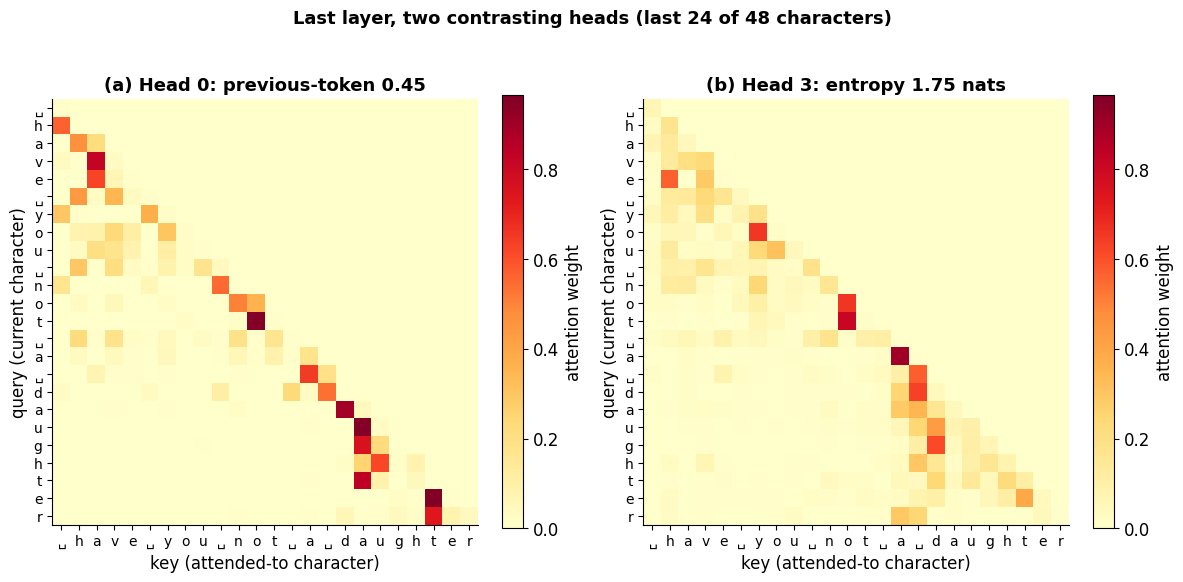

In [20]:
# P2.5a: score every last-layer head on one validation line, then pick two by the rule above.
LINE = next(ln for ln in TEXT[N_TR:].split("\n") if 40 <= len(ln) <= 60)
with torch.no_grad():
    W = LM(encode(LINE)[None].to(DEVICE), return_attn=True)[1][-1][0].cpu()  # last layer (H,L,L)
PREV = W.diagonal(offset=-1, dim1=-2, dim2=-1).mean(-1)  # (H,) mean w[t,t-1]
ENT = -(W * W.clamp_min(1e-12).log()).sum(-1).mean(-1)  # (H,) mean row entropy (nats)
HEAD_A = int(PREV.argmax())
HEAD_B = int(ENT.masked_fill(torch.arange(len(ENT)) == HEAD_A, -1).argmax())
print(f"line ({len(LINE)} chars): {LINE!r}")
display(
    pd.DataFrame(dict(head=range(len(ENT)), prev_token_weight=PREV.numpy().round(4), entropy_nats=ENT.numpy().round(4)))
)
print(f"head A (previous token) = {HEAD_A}, head B (most diffuse) = {HEAD_B}")

# P2-F4: heatmaps of the two chosen heads.
NSHOW = 24
CHS = [{" ": "␣"}.get(c, c) for c in LINE[-NSHOW:]]
Ws = W[:, -NSHOW:, -NSHOW:]
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, h, ttl in zip(axes, (HEAD_A, HEAD_B), (f"(a) Head {HEAD_A}: previous-token {PREV[HEAD_A]:.2f}",
                                              f"(b) Head {HEAD_B}: entropy {ENT[HEAD_B]:.2f} nats")):
    im = ax.imshow(Ws[h].numpy(), cmap="YlOrRd", vmin=0, vmax=float(Ws[[HEAD_A, HEAD_B]].max()))
    ax.grid(False)
    ax.set_xticks(range(NSHOW), CHS, fontsize=10)
    ax.set_yticks(range(NSHOW), CHS, fontsize=10)
    ax.set_xlabel("key (attended-to character)")
    ax.set_ylabel("query (current character)")
    ax.set_title(ttl)
    fig.colorbar(im, ax=ax, fraction=0.046, label="attention weight")
fig.suptitle(
    f"Last layer, two contrasting heads (last {NSHOW} of {len(LINE)} characters)", fontweight="bold", fontsize=13
)
fig.tight_layout()
save(fig, "p2_fig04_heads_heatmap")
plt.show()

The two heads (P2-F4). Both come from the last layer and were scored on one validation line with the rule above. Head 0 has the highest mean previous-token weight (0.45) and the lowest entropy (1.08 nats), so most of its attention goes to the character just before. Head 3 has the highest entropy (1.75 nats) and a previous-token weight of only 0.20, so it spreads its attention over many earlier characters. Heads 1 and 2 are in between (entropy 1.39 and 1.46 nats). Heads in the same layer end up doing different jobs: one looks locally, the other looks broadly.

### P2.5b Number of heads (d = 128 fixed)
1, 4 and 8 heads (head size 128, 32 and 16). Each is a new run with the same short budget of 1,500 steps and otherwise the P2.4 settings. The projections are always d×d, so all three have the same parameter count, which the cell checks.

[P2.5b heads=1] step   100 train 3.1669 val 2.5574 (3.689 bpc) 3s
[P2.5b heads=1] step   200 train 2.4745 val 2.3294 (3.361 bpc) 5s
[P2.5b heads=1] step   300 train 2.2815 val 2.1852 (3.153 bpc) 8s
[P2.5b heads=1] step   400 train 2.1478 val 2.0867 (3.010 bpc) 11s
[P2.5b heads=1] step   500 train 2.0430 val 2.0118 (2.902 bpc) 13s
[P2.5b heads=1] step   600 train 1.9575 val 1.9612 (2.829 bpc) 16s
[P2.5b heads=1] step   700 train 1.9000 val 1.9163 (2.765 bpc) 19s
[P2.5b heads=1] step   800 train 1.8465 val 1.8811 (2.714 bpc) 22s
[P2.5b heads=1] step   900 train 1.8073 val 1.8638 (2.689 bpc) 25s
[P2.5b heads=1] step  1000 train 1.7812 val 1.8360 (2.649 bpc) 28s
[P2.5b heads=1] step  1100 train 1.7559 val 1.8269 (2.636 bpc) 31s
[P2.5b heads=1] step  1200 train 1.7433 val 1.8141 (2.617 bpc) 34s
[P2.5b heads=1] step  1300 train 1.7314 val 1.8084 (2.609 bpc) 36s
[P2.5b heads=1] step  1400 train 1.7212 val 1.8045 (2.603 bpc) 39s
[P2.5b heads=1] step  1500 train 1.7159 val 1.7956 (2.591 bpc) 42

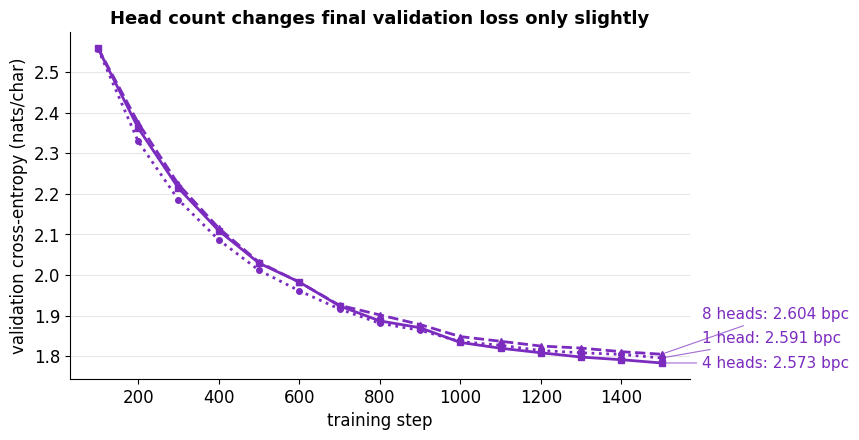

In [21]:
# P2.5b: 1, 4 and 8 heads with the same short budget.
EVAL_SHORT = 1 if SMOKE else 100
HEADS = {h: run_cached("P2.5b", "Transformer", 7, CTX, f"d={D},heads={h},steps={SHORT_STEPS}",
                       lambda h=h: run_lm(lambda: CharTransformer(n_heads=h), SHORT_STEPS, EVAL_SHORT, f"P2.5b heads={h}"))
         for h in (1, 4, 8)}
assert len({o["row"]["params"] for o in HEADS.values()}) == 1, "parameter count must not depend on the head count"
for h, o in HEADS.items():
    print(
        f"heads={h}: val {o['row']['val_loss_nats']:.4f} nats = {o['row']['bits_per_char']:.4f} bpc | params {o['row']['params']:,}"
    )

# P2-F5: validation loss for each head count.
fig, ax = plt.subplots(figsize=(8, 4.5))
ends = []
for (h, o), ls, mk in zip(HEADS.items(), (":", "-", "--"), ("o", "s", "^")):
    hh = o["history"]
    ax.plot(hh["step"], hh["val_loss"], color=COLORS["Transformer"], ls=ls, lw=2, marker=mk, ms=4)
    ends.append((hh["step"][-1], hh["val_loss"][-1], f"{h} head{'s' * (h > 1)}: {o['row']['bits_per_char']:.3f} bpc",
                 COLORS["Transformer"]))
end_labels(ax, ends)
ax.set_xlabel("training step")
ax.set_ylabel("validation cross-entropy (nats/char)")
ax.set_title("Head count changes final validation loss only slightly")
save(fig, "p2_fig05_heads_ablation")
plt.show()

Reading P2-F5. After the same 1,500 steps the validation loss is 1.796 nats with 1 head, 1.783 with 4 and 1.805 with 8. That 0.02-nat spread comes from a single seed, so I do not name a winner. All three models have 810,049 parameters, because the four d × d projections do not depend on the number of heads. The heads only cut d into H slices of size d/H.

### P2.5c No causal mask
The same model with `causal=False` (4 heads), trained with the same short budget and seed as the 4-head run in P2.5b, which serves as the baseline.

[P2.5c no mask] step   100 train 3.1641 val 2.5589 (3.692 bpc) 3s
[P2.5c no mask] step   200 train 2.4841 val 2.3058 (3.327 bpc) 6s
[P2.5c no mask] step   300 train 1.5948 val 0.4228 (0.610 bpc) 10s
[P2.5c no mask] step   400 train 0.3949 val 0.1023 (0.148 bpc) 13s
[P2.5c no mask] step   500 train 0.1780 val 0.0488 (0.070 bpc) 16s
[P2.5c no mask] step   600 train 0.1130 val 0.0339 (0.049 bpc) 19s
[P2.5c no mask] step   700 train 0.0850 val 0.0272 (0.039 bpc) 22s
[P2.5c no mask] step   800 train 0.0671 val 0.0245 (0.035 bpc) 26s
[P2.5c no mask] step   900 train 0.0570 val 0.0229 (0.033 bpc) 29s
[P2.5c no mask] step  1000 train 0.0517 val 0.0225 (0.032 bpc) 32s
[P2.5c no mask] step  1100 train 0.0470 val 0.0219 (0.032 bpc) 35s
[P2.5c no mask] step  1200 train 0.0444 val 0.0214 (0.031 bpc) 39s
[P2.5c no mask] step  1300 train 0.0426 val 0.0212 (0.031 bpc) 43s
[P2.5c no mask] step  1400 train 0.0405 val 0.0209 (0.030 bpc) 47s
[P2.5c no mask] step  1500 train 0.0399 val 0.0208 (0.030 bpc) 5

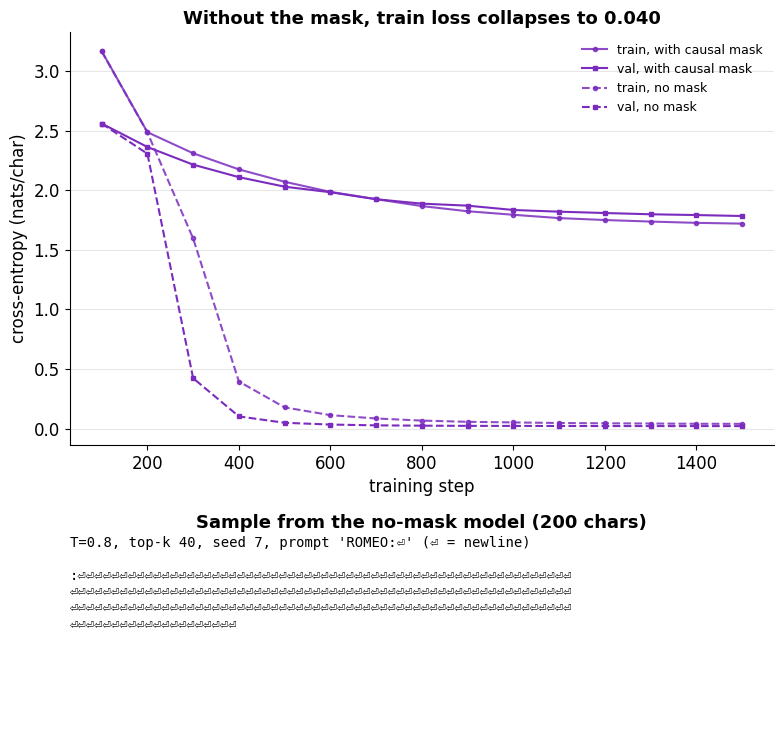

In [22]:
# P2.5c: same model and budget, no causal mask.
NOMASK = run_cached("P2.5c", "Transformer", 7, CTX, f"d={D},heads=4,mask=off,steps={SHORT_STEPS}",
                    lambda: run_lm(lambda: CharTransformer(causal=False), SHORT_STEPS, EVAL_SHORT, "P2.5c no mask"))
NM_SAMPLE = generate(load_lm(lambda: CharTransformer(causal=False), NOMASK), n=200)
hm, hn = HEADS[4]["history"], NOMASK["history"]
print(f"final train loss: with mask {hm['train_loss'][-1]:.4f} | without {hn['train_loss'][-1]:.4f}")
print(
    f"final val loss (computed by the same model, so leaky without the mask): with {hm['val_loss'][-1]:.4f} | without {hn['val_loss'][-1]:.4f}"
)
print(f"no-mask sample: {NM_SAMPLE!r}")

# P2-F6: loss curves on top, the no-mask sample below.
fig, (ax, bx) = plt.subplots(2, 1, figsize=(8, 7.5), gridspec_kw=dict(height_ratios=[2.2, 1]))
for hh, ls, lab in ((hm, "-", "with causal mask"), (hn, "--", "no mask")):
    ax.plot(
        hh["step"],
        hh["train_loss"],
        color=COLORS["Transformer"],
        ls=ls,
        alpha=0.85,
        marker="o",
        ms=3,
        label=f"train, {lab}",
    )
    ax.plot(hh["step"], hh["val_loss"], color=COLORS["Transformer"], ls=ls, marker="s", ms=3, label=f"val, {lab}")
ax.set_xlabel("training step")
ax.set_ylabel("cross-entropy (nats/char)")
ax.set_title(f"Without the mask, train loss collapses to {hn['train_loss'][-1]:.3f}")
ax.legend(frameon=False, fontsize=9)
bx.axis("off")
bx.text(0, 1, f"T=0.8, top-k 40, seed 7, prompt 'ROMEO:⏎' (⏎ = newline)\n\n{textwrap.fill(NM_SAMPLE.replace(chr(10), '⏎'), 60)}",
        family="monospace", fontsize=10, va="top", transform=bx.transAxes)
bx.set_title("Sample from the no-mask model (200 chars)")
fig.tight_layout()
save(fig, "p2_fig06_no_mask")
plt.show()

Why the mask matters. Without it, every position in training can attend to later positions, including the character it is supposed to predict, so the model learns to copy the answer. During generation those future characters do not exist yet, so the model gets inputs unlike anything it saw in training, and the samples fall apart. The validation loss is computed by the same model on full windows, so it can look ahead too and comes out low as well. That low number is leakage and says nothing about how well the model predicts text. In our run (P2-F6) the final train loss is 0.040 without the mask and 1.719 with it, the leaky validation loss is 0.021 nats, and the no-mask sample is a single colon followed by nothing but newlines.

### P2.5d Context length vs time and memory
Same model as P2.4, fed random token batches of shape (64, n). For each n we time 10 forward and backward steps after 3 warm-up steps and take the mean, and we record peak allocated memory, reset before each n. These probes take seconds, so they are not cached, and a rerun replaces the four CSV rows.

,ctx,ms_per_step,peak_MB
0,64,19.0,202.0
1,128,33.2,407.0
2,256,85.4,950.0
3,512,242.6,2766.0


device cuda | fitted log-log slope: time 1.24, memory 1.25
saved figures/p2_fig07_context_scaling.png


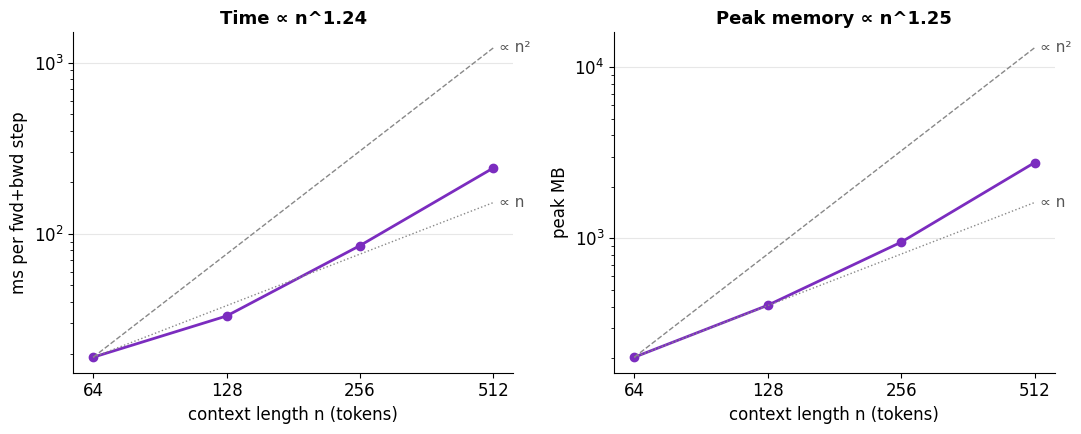

In [23]:
# P2.5d: time and peak memory of one training step for each context length.
CTXS = [64, 128, 256, 512]
WARM, TIMED = (1, 2) if SMOKE else (3, 10)
with open(CSV_PATH, newline="") as f:  # drop old P2.5d rows: their notes hold measured values, so keys differ per run
    old = [r for r in csv.DictReader(f) if r["problem"] != "P2.5d"]
with open(CSV_PATH, "w", newline="") as f:
    w = csv.DictWriter(f, COLUMNS)
    w.writeheader()
    w.writerows(old)

# Measure each context length with a fresh model.
MS, MB = [], []
for n in CTXS:
    seed_all(7)
    model = CharTransformer().to(DEVICE).train()
    x, y = (torch.randint(0, V, (64, n), device=DEVICE) for _ in range(2))
    if DEVICE.type != "cpu":
        torch.accelerator.memory.reset_peak_memory_stats()
    for i in range(WARM + TIMED):
        if i == WARM:
            sync()
            t0 = time.time()
        model.zero_grad(set_to_none=True)
        F.cross_entropy(model(x).reshape(-1, V), y.reshape(-1)).backward()
    sync()
    MS.append((time.time() - t0) / TIMED * 1000)
    MB.append(torch.accelerator.memory.max_memory_allocated() / 2**20 if DEVICE.type != "cpu" else float("nan"))
    upsert_row(dict(problem="P2.5d", model="Transformer", seed=7, seq_len=n, params=n_params(model),
                    notes=f"ctx={n},ms={MS[-1]:.1f},MB={MB[-1]:.0f}"))
    del model
SLOPE_T, SLOPE_M = (np.polyfit(np.log(CTXS), np.log(v), 1)[0] for v in (MS, MB))
display(pd.DataFrame(dict(ctx=CTXS, ms_per_step=np.round(MS, 1), peak_MB=np.round(MB, 0))))
print(f"device {DEVICE.type} | fitted log-log slope: time {SLOPE_T:.2f}, memory {SLOPE_M:.2f}")

# P2-F7: log-log plots with n and n^2 guide lines.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, ys, slope, name, unit in ((axes[0], MS, SLOPE_T, "Time", "ms per fwd+bwd step"),
                                  (axes[1], MB, SLOPE_M, "Peak memory", "peak MB")):
    ax.plot(CTXS, ys, color=COLORS["Transformer"], marker="o", lw=2)
    for k, ls in ((1, ":"), (2, "--")):
        guide = ys[0] * (np.array(CTXS) / CTXS[0]) ** k  # anchored at the first point
        ax.plot(CTXS, guide, color=COLORS["ref"], ls=ls, lw=1)
        ax.annotate("∝ n²" if k == 2 else "∝ n", (CTXS[-1], guide[-1]), xytext=(4, 0), textcoords="offset points",
                    color="#555555", fontsize=11, va="center")
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xticks(CTXS, CTXS)
    ax.set_xlabel("context length n (tokens)")
    ax.set_ylabel(unit)
    ax.set_title(f"{name} ∝ n^{slope:.2f}")
fig.tight_layout()
save(fig, "p2_fig07_context_scaling")
plt.show()

Context length (P2-F7). The attention score matrix costs O(n² · d) per layer, while the embeddings, the four projections and the FFN cost O(n · d²). Between n = 64 and n = 512 the fitted log-log slopes are 1.24 for time and 1.25 for peak memory, both below 2. With d = 128 and these short contexts the linear terms still account for much of the cost, so the curves are only starting to bend toward n². The bend shows in the step-by-step ratios. Time goes from 19.0 ms at n = 64 to 33.2, 85.4 and 242.6 ms, so each doubling costs 1.7, 2.6 and 2.8 times more, moving toward the quadratic factor of 4. Peak memory goes from 202 MB to 407, 950 and 2,766 MB (2.0, 2.3 and 2.9 times per doubling). For longer contexts the n² term would dominate, and attention memory would limit how long the context can be.

## Bonus: LSTM vs Transformer on Tiny Shakespeare
`LSTMChar` is `Embedding(65,128)`, then `nn.LSTM(128, 256, 2 layers, dropout 0.1)`, then `Linear(256,65)`. The library LSTM is allowed here. It uses the same data windows (context 128), batch size, step budget, optimiser, schedule, evaluation and generation as P2.4, through the same `run_lm`.

[BONUS] step   250 train 2.8417 val 2.0525 (2.961 bpc) 7s
[BONUS] step   500 train 1.8267 val 1.7958 (2.591 bpc) 13s
[BONUS] step   750 train 1.6174 val 1.6866 (2.433 bpc) 20s
[BONUS] step  1000 train 1.5225 val 1.6253 (2.345 bpc) 26s
[BONUS] step  1250 train 1.4619 val 1.5958 (2.302 bpc) 32s
[BONUS] step  1500 train 1.4211 val 1.5694 (2.264 bpc) 39s
[BONUS] step  1750 train 1.3874 val 1.5496 (2.236 bpc) 45s
[BONUS] step  2000 train 1.3637 val 1.5342 (2.213 bpc) 52s
[BONUS] step  2250 train 1.3456 val 1.5262 (2.202 bpc) 58s
[BONUS] step  2500 train 1.3274 val 1.5191 (2.192 bpc) 64s
[BONUS] step  2750 train 1.3135 val 1.5139 (2.184 bpc) 70s
[BONUS] step  3000 train 1.3010 val 1.5034 (2.169 bpc) 77s
[BONUS] step  3250 train 1.2898 val 1.5053 (2.172 bpc) 83s
[BONUS] step  3500 train 1.2777 val 1.5023 (2.167 bpc) 89s
[BONUS] step  3750 train 1.2728 val 1.4999 (2.164 bpc) 95s
[BONUS] step  4000 train 1.2677 val 1.4981 (2.161 bpc) 102s
[BONUS] step  4250 train 1.2607 val 1.4991 (2.163 bpc) 1

**P2-T3** LSTM vs Transformer, 5000 steps, same protocol

,model,params,val nats,bits/char,train s,tokens/s
0,Transformer,"810,049",1.5590,2.249,165,"248,377"
1,LSTM-char,"946,625",1.4963,2.159,128,"320,688"


saved figures/p2_fig08_bonus_lstm_vs_tf.png


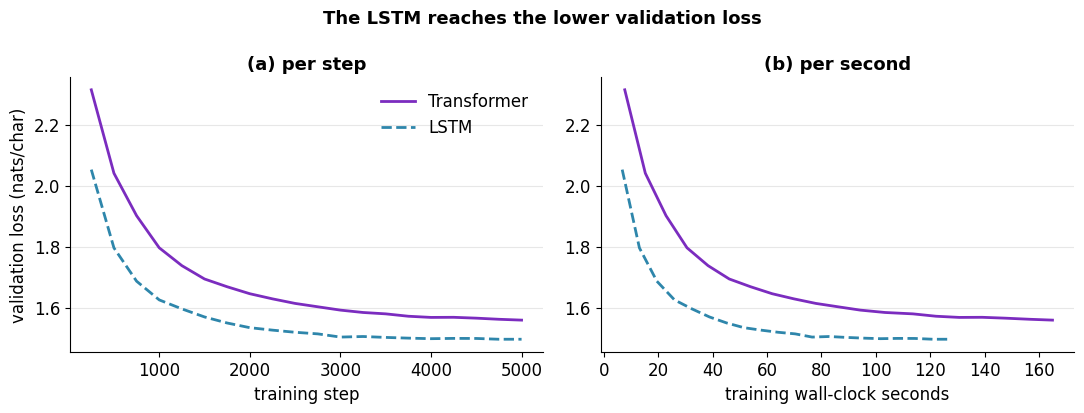

--- Transformer, T=0.8 ---
At 'tis encounters, I have so not streets him be now?

CLARENCE:
Romeo, sir; yet she cause the behold that we may return.

MENENIUS:
Well, now, trage own the most wester thou resk?

ESCALUS:
What they do unto the vintoney thus and shall be
And the friends with and simple are confession.
In thou dost

--- LSTM, T=0.8 ---
At 'Tantis of those that set with the mouths?
We must your storm and honour have shums of love,
I'll freather malice beggar'd in the poor world--
Who swort thus but son that vessel will vill
With thee drought to the sons, that will be
day shall be from the softing; but not once,
To die. In this done


In [24]:
# Bonus model: embedding, 2-layer LSTM, linear head.
class LSTMChar(nn.Module):
    def __init__(self, vocab=V, d=D, hid=256, layers=2, dropout=0.1):
        super().__init__()
        self.emb = nn.Embedding(vocab, d)
        self.rnn = nn.LSTM(d, hid, layers, batch_first=True, dropout=dropout)
        self.head = nn.Linear(hid, vocab)

    def forward(self, idx):  # (B,L) -> (B,L,vocab)
        return self.head(self.rnn(self.emb(idx))[0])


# Same data, budget and protocol as P2.4; then P2-T3.
BON = run_cached("BONUS", "LSTM-char", 7, CTX, f"d={D},hid=256,layers=2,steps={LM_STEPS}",
                 lambda: run_lm(LSTMChar, LM_STEPS, EVAL_EVERY, "BONUS"))
LSTM_LM = load_lm(LSTMChar, BON)
display(Markdown(f"**P2-T3** LSTM vs Transformer, {LM_STEPS} steps, same protocol"), pd.DataFrame(
    [(name, f"{o['row']['params']:,}", f"{o['row']['val_loss_nats']:.4f}", f"{o['row']['bits_per_char']:.3f}",
      f"{o['artifacts']['train_sec']:.0f}", f"{o['artifacts']['tokens_per_s']:,.0f}") for name, o in (("Transformer", LM_OUT), ("LSTM-char", BON))],
    columns=["model", "params", "val nats", "bits/char", "train s", "tokens/s"]))

# P2-F8: validation loss per step and per second of training.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
for o, name, ls in ((LM_OUT, "Transformer", "-"), (BON, "LSTM", "--")):
    hh = o["history"]
    ax1.plot(hh["step"], hh["val_loss"], color=COLORS[name], ls=ls, lw=2, label=name)
    ax2.plot(hh["wall"], hh["val_loss"], color=COLORS[name], ls=ls, lw=2, label=name)
ax1.set_xlabel("training step")
ax2.set_xlabel("training wall-clock seconds")
ax1.set_ylabel("validation loss (nats/char)")
ax1.set_title("(a) per step")
ax2.set_title("(b) per second")
ax1.legend(frameon=False)
win = "Transformer" if LM_OUT["row"]["val_loss_nats"] < BON["row"]["val_loss_nats"] else "LSTM"
fig.suptitle(f"The {win} reaches the lower validation loss", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "p2_fig08_bonus_lstm_vs_tf")
plt.show()
print("--- Transformer, T=0.8 ---\n" + generate(LM, 300) + "\n\n--- LSTM, T=0.8 ---\n" + generate(LSTM_LM, 300))

Reading P2-T3 and P2-F8. With the same data, budget, optimiser, schedule and evaluation, the 2-layer LSTM (946,625 parameters) ends at 1.496 nats (2.159 bits/char) and the Transformer (810,049 parameters) at 1.559 nats (2.249 bits/char). The LSTM also trains faster on the T4: 320,688 against 248,377 tokens/s, or 128 s against 165 s. It has 17% more parameters, which may explain part of the gap. At this small size and a context of 128, the Transformer's parallel attention does not make it faster than cuDNN's fused LSTM.